# Project 11 — US Treasury yield curve model and bond portfolio scenario tool
Curve date: 30 September 2026. Data: U.S. Treasury Daily Par Yield Curve Rates (2006–2026),
Federal Reserve Gürkaynak-Sack-Wright (GSW) zero curve, NBER recessions (FRED USREC).

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent)]

import numpy as np
import pandas as pd

from common import data as D
from common.plotting import PALETTE, setup, source
from yieldcurve import bonds as B, curve as C, scenarios as S

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
DATE = pd.Timestamp("2026-09-30")
SRC_T = "Source: U.S. Treasury Daily Par Yield Curve Rates; author's calculations."
par_all = pd.read_csv(DATA / "treasury_par_yields_daily.csv", index_col=0, parse_dates=True).loc["2006":"2026-09-30"]
gsw = pd.read_csv(DATA / "gsw_zero_curve_2006_2026.csv", index_col=0, parse_dates=True)
rec = D.fred("USREC", DATA / "fred_USREC.csv")["USREC"]
print(par_all.index[0].date(), "to", par_all.index[-1].date(), len(par_all), "days")

2006-01-03 to 2026-09-30 5192 days


## 1. Bootstrap the zero curve on 30 September 2026

In [2]:
par = C.par_points(par_all.loc[DATE])
zc = C.ZeroCurve(par)
grid = zc.grid
boot = pd.DataFrame({"Par (spline)": zc.par_grid, "Discount factor": zc.df_grid,
                     "Zero (semiannual)": zc.zero_sa(grid), "Zero (continuous)": zc.zero_cc(grid)}, index=grid)
boot.index.name = "Maturity (years)"
check = max(abs(zc.par_yield(T) - zc.spline(T)) for T in grid)
print(f"Max repricing error of par bonds on the grid: {check * 1e4:.2e} bp")
boot.loc[[0.5, 1, 2, 3, 5, 7, 10, 20, 30]]

Max repricing error of par bonds on the grid: 1.67e-12 bp


,Par (spline),Discount factor,Zero (semiannual),Zero (continuous)
Maturity (years),,,,
0.5,0.0433,0.978809,0.043300,0.042838
1.0,0.0454,0.956078,0.045424,0.044916
2.0,0.0488,0.907899,0.048899,0.048311
3.0,0.0500,0.861971,0.050129,0.049511
5.0,0.0509,0.777193,0.051054,0.050413
7.0,0.0519,0.697361,0.052162,0.051493
10.0,0.0529,0.590914,0.053307,0.052609
20.0,0.0568,0.313773,0.058802,0.057954
30.0,0.0564,0.185471,0.056958,0.056162


## 2. Nelson-Siegel-Svensson by nonlinear least squares; comparison with the Fed (GSW) curve

In [3]:
nss_p, nss_rmse = C.fit_nss(par)
g = gsw.loc[DATE]
cmp_rows = {}
for T in (2, 5, 10, 30):
    mine = float(C.nss_zero(np.array([T]), *nss_p)[0])
    boot_z = float(zc.zero_cc(T))
    fed = g[f"SVENY{T:02d}"] / 100
    cmp_rows[f"{T}y"] = {"NSS (this fit)": mine, "Bootstrap": boot_z, "Fed GSW": fed,
                         "NSS − GSW (bp)": (mine - fed) * 1e4, "Bootstrap − GSW (bp)": (boot_z - fed) * 1e4}
CMP = pd.DataFrame(cmp_rows).T
NSSP = pd.Series(nss_p, ["beta0", "beta1", "beta2", "beta3", "tau1", "tau2"])
GSWP = pd.Series([g["BETA0"] / 100, g["BETA1"] / 100, g["BETA2"] / 100, g["BETA3"] / 100, g["TAU1"], g["TAU2"]], NSSP.index)
print(f"NSS fit RMSE on par yields: {nss_rmse * 1e4:.2f} bp")
pd.DataFrame({"This fit": NSSP, "Fed GSW": GSWP}), CMP

NSS fit RMSE on par yields: 2.81 bp


(           This fit       Fed GSW
 beta0  5.129376e-15  2.220638e-16
 beta1  3.959693e-02  3.927770e-02
 beta2  4.984728e-02  5.270320e-02
 beta3  1.695294e-01  1.709282e-01
 tau1   2.054817e+00  1.864550e+00
 tau2   1.616265e+01  1.570252e+01,
      NSS (this fit)  Bootstrap   Fed GSW  NSS − GSW (bp)  Bootstrap − GSW (bp)
 2y         0.048004   0.048311  0.048390       -3.858523             -0.790237
 5y         0.050552   0.050413  0.050416        1.361544             -0.026359
 10y        0.052954   0.052609  0.052836        1.178413             -2.274909
 30y        0.056694   0.056162  0.056644        0.503533             -4.821602)

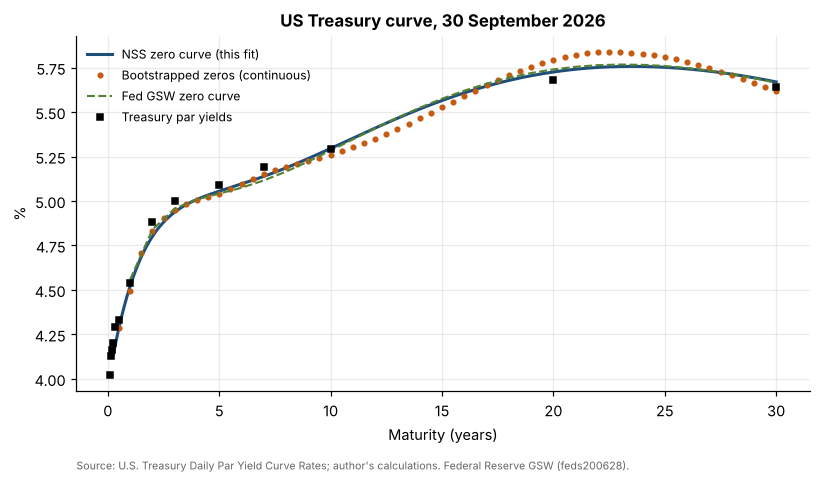

In [4]:
fig, ax = plt.subplots(figsize=(8.6, 4.2))
tt = np.linspace(0.25, 30, 300)
ax.plot(tt, C.nss_zero(tt, *nss_p) * 100, color=PALETTE[0], lw=2, label="NSS zero curve (this fit)")
ax.plot(grid, zc.zero_cc(grid) * 100, "o", ms=3, color=PALETTE[1], label="Bootstrapped zeros (continuous)")
ax.plot(range(1, 31), [g[f"SVENY{i:02d}"] for i in range(1, 31)], "--", color=PALETTE[2], lw=1.4, label="Fed GSW zero curve")
ax.plot(par.index, par.values * 100, "s", ms=4, color="black", label="Treasury par yields")
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("%"); ax.legend(fontsize=8)
ax.set_title("US Treasury curve, 30 September 2026")
source(ax, SRC_T + " Federal Reserve GSW (feds200628).")
fig.savefig(FIG / "fig_curve.png"); plt.show()

## 3. Daily Nelson-Siegel fit 2006–2026: level, slope, curvature

In [5]:
STD = ["1 Mo", "3 Mo", "6 Mo", "1 Yr", "2 Yr", "3 Yr", "5 Yr", "7 Yr", "10 Yr", "20 Yr", "30 Yr"]
ns_rows, ns_rmse = {}, {}
for d, row in par_all[STD].iterrows():
    p = C.par_points(row)
    if len(p) < 6:
        continue
    b = C.fit_ns_ols(p)
    ns_rows[d] = b
    ns_rmse[d] = np.sqrt(np.mean((C.ns_loadings(p.index.values, 1 / 0.7308) @ b - p.values) ** 2))
NS = pd.DataFrame(ns_rows, index=["Level", "Slope", "Curvature"]).T
NS["RMSE (bp)"] = pd.Series(ns_rmse) * 1e4
print(f"{len(NS)} daily fits; median RMSE {NS['RMSE (bp)'].median():.1f} bp, 95th pct {NS['RMSE (bp)'].quantile(.95):.1f} bp")
NS.describe().T

5191 daily fits; median RMSE 9.4 bp, 95th pct 20.7 bp


,count,mean,std,min,25%,50%,75%,max
Level,5191.0,0.036635,0.010699,0.009703,0.028790,0.035992,0.047103,0.056496
Slope,5191.0,-0.018147,0.017369,-0.052777,-0.030586,-0.019433,-0.004376,0.022027
Curvature,5191.0,-0.026916,0.022088,-0.075459,-0.044218,-0.024444,-0.012868,0.041473
RMSE (bp),5191.0,10.492347,5.464028,1.895669,6.378933,9.417582,12.925255,48.704268


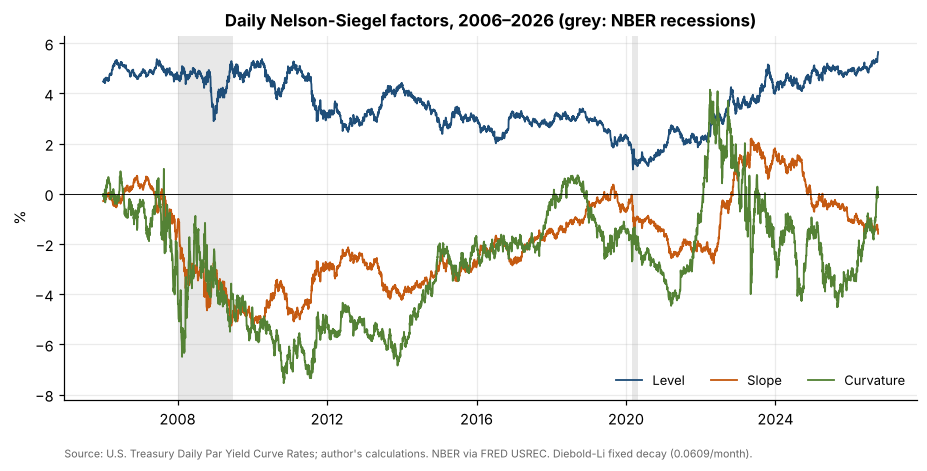

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.3))
r = rec.loc["2006":"2026-09"]
for start, grp in r[r == 1].groupby((r != 1).cumsum()):
    ax.axvspan(grp.index[0], grp.index[-1] + pd.offsets.MonthEnd(0), color="grey", alpha=0.18, lw=0)
for i, c in enumerate(["Level", "Slope", "Curvature"]):
    ax.plot(NS.index, NS[c] * 100, lw=1.2, color=PALETTE[i], label=c)
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("%"); ax.legend(ncol=3, fontsize=8.5)
ax.set_title("Daily Nelson-Siegel factors, 2006–2026 (grey: NBER recessions)")
source(ax, SRC_T + " NBER via FRED USREC. Diebold-Li fixed decay (0.0609/month).")
fig.savefig(FIG / "fig_ns_factors.png"); plt.show()

## 4. PCA on daily yield changes (1, 2, 3, 5, 7, 10, 20, 30y)

In [7]:
PCA_T = ["1 Yr", "2 Yr", "3 Yr", "5 Yr", "7 Yr", "10 Yr", "20 Yr", "30 Yr"]
dY = par_all[PCA_T].diff().dropna() * 100   # basis points
cov = np.cov(dY.values.T)
ev, evec = np.linalg.eigh(cov)
order = ev.argsort()[::-1]
ev, evec = ev[order], evec[:, order]
evec = evec * np.sign(evec.sum(axis=0))  # level loads positively
evec[:, 1] *= np.sign(evec[-1, 1] - evec[0, 1])  # slope: long end up
expl = ev / ev.sum()
PCA = pd.DataFrame(evec[:, :3], index=PCA_T, columns=["PC1 (level)", "PC2 (slope)", "PC3 (curvature)"])
print("Variance explained:", np.round(expl[:5], 4), "cumulative 3:", round(expl[:3].sum(), 4), "| days:", len(dY))
PCA

Variance explained: [0.845  0.1102 0.024  0.0097 0.0047] cumulative 3: 0.9792 | days: 5163


,PC1 (level),PC2 (slope),PC3 (curvature)
1 Yr,0.189410,-0.447028,0.780277
2 Yr,0.315373,-0.473089,-0.015254
3 Yr,0.360934,-0.357564,-0.218689
5 Yr,0.408625,-0.125484,-0.326377
7 Yr,0.417493,0.062787,-0.250074
10 Yr,0.391807,0.223348,-0.061125
20 Yr,0.355223,0.413969,0.234515
30 Yr,0.336778,0.455585,0.339585


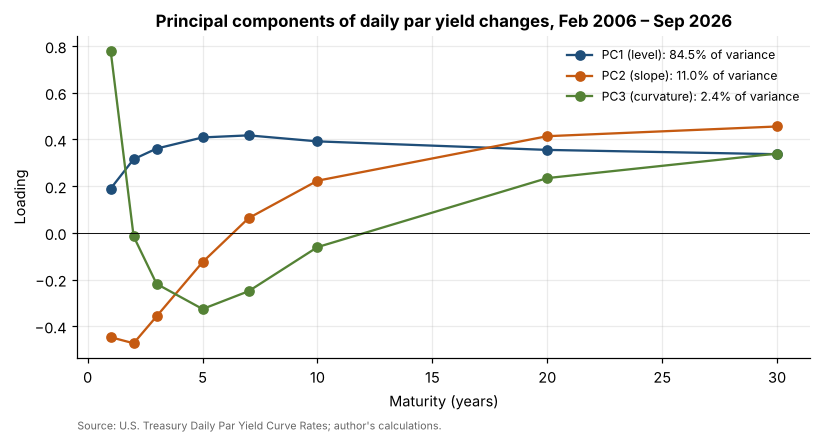

In [8]:
fig, ax = plt.subplots(figsize=(8.6, 3.8))
mats = [1, 2, 3, 5, 7, 10, 20, 30]
for i, c in enumerate(PCA.columns):
    ax.plot(mats, PCA[c], "o-", color=PALETTE[i], label=f"{c}: {expl[i]:.1%} of variance")
ax.axhline(0, color="black", lw=0.6); ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Loading")
ax.set_title(f"Principal components of daily par yield changes, {dY.index[0]:%b %Y} – {dY.index[-1]:%b %Y}")
ax.legend(fontsize=8)
source(ax, SRC_T)
fig.savefig(FIG / "fig_pca.png"); plt.show()

## 5. Three $100m portfolios priced off the 30 September 2026 curve

In [9]:
bullet_b = B.par_bond(zc, 7)
b2, b30 = B.par_bond(zc, 2), B.par_bond(zc, 30)
D7 = bullet_b.mod_duration_convexity(bullet_b.coupon)[0]
D2 = b2.mod_duration_convexity(b2.coupon)[0]
D30 = b30.mod_duration_convexity(b30.coupon)[0]
w30 = (D7 - D2) / (D30 - D2)              # par bonds: market value = face, so weights are by face
NOT = 100e6
PORTS = {"Bullet": B.Portfolio([bullet_b], [NOT]),
         "Barbell": B.Portfolio([b2, b30], [NOT * (1 - w30), NOT * w30]),
         "Ladder": B.Portfolio([B.par_bond(zc, k) for k in range(1, 11)], [NOT / 10] * 10)}
desc = {}
for k, pt in PORTS.items():
    conv = sum(n / pt.value(zc) * b.mod_duration_convexity(b.coupon)[1] * b.price(zc) / b.face for b, n in zip(pt.bonds, pt.notionals))
    y = sum(n * b.coupon for b, n in zip(pt.bonds, pt.notionals)) / pt.notionals.sum()
    desc[k] = {"Value ($m)": pt.value(zc) / 1e6, "Modified duration": pt.mod_duration(zc), "Convexity": conv,
               "Average coupon / yield": y,
               "Holdings": ", ".join(f"{b.maturity:g}y {n / 1e6:.1f}m @ {b.coupon:.3%}" for b, n in zip(pt.bonds, pt.notionals))}
PDESC = pd.DataFrame(desc).T
PDESC

,Value ($m),Modified duration,Convexity,Average coupon / yield,Holdings
Bullet,100.0,5.807177,40.100824,0.0519,7y 100.0m @ 5.190%
Barbell,100.0,5.807177,102.006379,0.051185,"2y 68.6m @ 4.880%, 30y 31.4m @ 5.640%"
Ladder,100.0,4.572147,30.712372,0.050671,"1y 10.0m @ 4.540%, 2y 10.0m @ 4.880%, 3y 10.0m..."


## 6–7. Six instant scenarios: full revaluation vs. duration vs. duration + convexity; key rate durations

In [10]:
rows = []
for sc, fn in S.SCENARIOS.items():
    for k, pt in PORTS.items():
        res = S.portfolio_pnl(pt, zc, fn)
        rows.append({"Scenario": sc, "Portfolio": k, **{f"{m} ($m)": v / 1e6 for m, v in res.items()},
                     "Full revaluation (bp of value)": res["Full revaluation"] / pt.value(zc) * 1e4})
PNL = pd.DataFrame(rows)
KRD = pd.DataFrame({k: S.key_rate_durations(pt, zc) for k, pt in PORTS.items()}).T
KRD["Sum of KRDs"] = KRD.sum(axis=1)
KRD["Modified duration"] = PDESC["Modified duration"]
PNL.pivot(index="Scenario", columns="Portfolio", values="Full revaluation (bp of value)").loc[list(S.SCENARIOS)], KRD

(Portfolio           Barbell      Bullet      Ladder
 Scenario                                           
 Parallel +100bp -542.434402 -576.093769 -453.935360
 Parallel -100bp  645.658935  615.289525  483.884523
 Bear steepener  -290.080476  -97.049801  -73.345245
 Bull flattener   366.120046   98.223278   74.649790
 Twist             38.998921 -197.870690 -158.795805
 Butterfly        -80.327062 -278.134853 -190.961591,
            KRD 2y    KRD 5y   KRD 10y   KRD 30y  Sum of KRDs Modified duration
 Bullet   0.295457  3.583732  2.073295 -0.000000     5.952484          5.807177
 Barbell  1.424812  0.294024  1.349079  2.829953     5.897868          5.807177
 Ladder   0.798805  2.074945  1.811644 -0.000000     4.685394          4.572147)

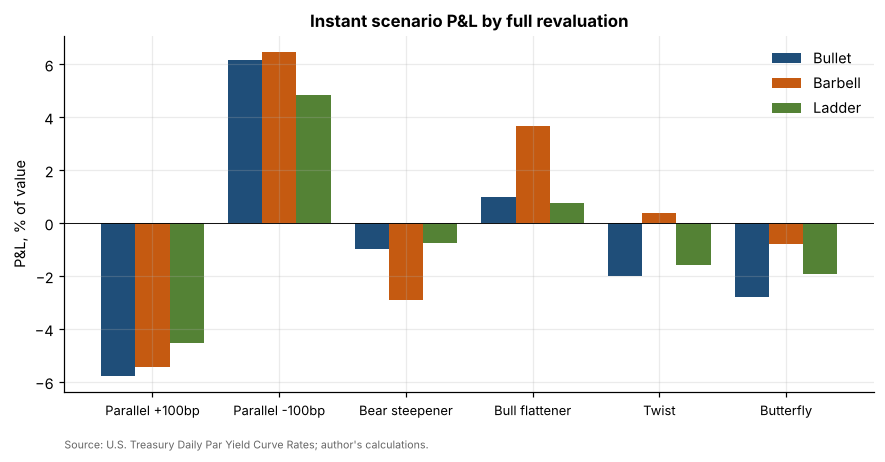

In [11]:
piv = PNL.pivot(index="Scenario", columns="Portfolio", values="Full revaluation (bp of value)").loc[list(S.SCENARIOS)]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
x = np.arange(len(piv))
for i, k in enumerate(["Bullet", "Barbell", "Ladder"]):
    ax.bar(x + (i - 1) * 0.27, piv[k] / 100, 0.27, label=k, color=PALETTE[i])
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(x, piv.index, fontsize=8.5); ax.set_ylabel("P&L, % of value")
ax.set_title("Instant scenario P&L by full revaluation"); ax.legend()
source(ax, SRC_T)
fig.savefig(FIG / "fig_scenarios.png"); plt.show()

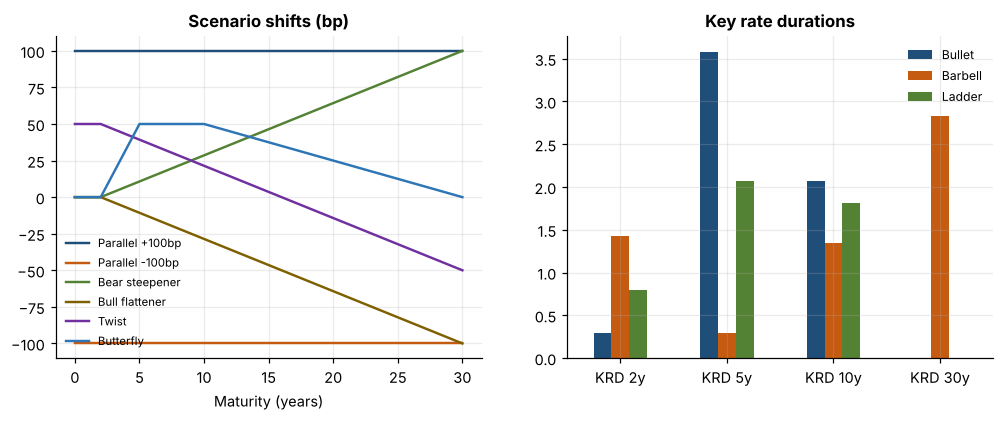

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for i, (sc, fn) in enumerate(S.SCENARIOS.items()):
    axes[0].plot(np.linspace(0, 30, 61), fn(np.linspace(0, 30, 61)) * 1e4, lw=1.6, color=PALETTE[i], label=sc)
axes[0].set_title("Scenario shifts (bp)"); axes[0].set_xlabel("Maturity (years)"); axes[0].legend(fontsize=7.5)
KRD[[c for c in KRD.columns if c.startswith("KRD")]].T.plot.bar(ax=axes[1], color=PALETTE[:3], rot=0)
axes[1].set_title("Key rate durations"); axes[1].legend(fontsize=8)
fig.savefig(FIG / "fig_shifts_krd.png"); plt.show()

## 8. 12-month horizon return with the curve unchanged: carry + roll-down

In [13]:
HOR = pd.DataFrame({k: S.horizon_return(pt, zc) for k, pt in PORTS.items()}).T
HOR

,Total,Carry,Roll-down
Bullet,0.054522,0.051900,0.002622
Barbell,0.052672,0.051185,0.001487
Ladder,0.052624,0.050671,0.001953


## Headline comparison: duration-matched barbell vs. bullet

In [14]:
diff = (piv["Barbell"] - piv["Bullet"]).rename("Barbell − bullet (bp)")
carry_gap = (HOR.loc["Barbell", "Total"] - HOR.loc["Bullet", "Total"]) * 1e4
best_sc = diff.idxmax()
print(f"Barbell beats bullet most in '{best_sc}': {diff.max():.0f} bp; 12-month carry+roll gap: {carry_gap:.0f} bp")
diff

Barbell beats bullet most in 'Bull flattener': 268 bp; 12-month carry+roll gap: -19 bp


Scenario
Parallel +100bp     33.659367
Parallel -100bp     30.369410
Bear steepener    -193.030675
Bull flattener     267.896767
Twist              236.869611
Butterfly          197.807791
Name: Barbell − bullet (bp), dtype: float64

## Save

In [15]:
boot.to_csv(DATA / "bootstrap_2026-09-30.csv"); CMP.to_csv(DATA / "nss_vs_gsw.csv")
pd.DataFrame({"This fit": NSSP, "Fed GSW": GSWP}).to_csv(DATA / "nss_parameters.csv")
NS.to_csv(DATA / "ns_daily_factors.csv"); PCA.to_csv(DATA / "pca_loadings.csv")
PDESC.to_csv(DATA / "portfolios.csv"); PNL.to_csv(DATA / "scenario_pnl.csv", index=False)
KRD.to_csv(DATA / "key_rate_durations.csv"); HOR.to_csv(DATA / "horizon_returns.csv"); diff.to_csv(DATA / "barbell_minus_bullet.csv")
json.dump({"date": str(DATE.date()), "nss_rmse_bp": nss_rmse * 1e4, "pca_explained": expl[:5].tolist(), "pca_days": len(dY),
           "ns_days": len(NS), "ns_median_rmse_bp": float(NS["RMSE (bp)"].median()), "barbell_w30": w30,
           "best_scenario": best_sc, "best_gain_bp": float(diff.max()), "carry_gap_bp": float(carry_gap),
           "max_boot_error_bp": float(check * 1e4)}, open(DATA / "meta.json", "w"), indent=2)